# Airway smooth muscle contraction

A transverse section of an airway wall is modelled as four hyperelastic layers around a free lumen.
Smooth muscle in the second layer pulls circumferentially with a tension set by Hai–Murphy
cross-bridge kinetics, and the wall is solved to static equilibrium at each time point.

After a 20 s kinase stimulus the lumen narrows by at most **4.09%**, at 30.5 s. Latch bridges hold
most of that narrowing while phosphorylation falls, and once the input is withdrawn the wall relaxes
on the 100 s timescale of latch detachment. Stiffer surrounding tissue resists contraction: at full
activation, narrowing falls from 13.9% to 2.9% as the non-muscle moduli increase sixteenfold.

Lengths, moduli and tension are dimensionless; time is in seconds. The model code is in
[`continuum.py`](continuum.py) and [`hai_murphy.py`](hai_murphy.py), with tests in `test_continuum.py`
and `test_hai_murphy.py`. Install `requirements-notebook.txt` and run all cells; it takes a few minutes.

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge

BACKEND = Path("backend") if Path("backend/continuum.py").is_file() else Path(".")
sys.path.insert(0, str(BACKEND.resolve()))
from continuum import ContinuumAirway
from hai_murphy import STATE_NAMES, ActivationProtocol, HaiMurphyRates, quasistatic_response, simulate

plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
LAYERS = {"mucosa": ("Mucosa and submucosa", "#b5bd8c"), "muscle": ("Smooth muscle", "#c4504a"),
          "cartilage": ("Cartilage", "#6aa5ae"), "adventitia": ("Adventitia", "#d9b354")}
STATE_COLORS = ["#8d8b84", "#b57924", "#b5452f", "#277d85"]
KINASE_COLOR = "#786198"

MODULI = {"mucosa": 25.0, "muscle": 50.0, "cartilage": 150.0, "adventitia": 75.0}
POISSON, T_MAX, TOLERANCE = 0.25, 20.0, 1e-7
WORKING, FINEST = (20, 80), (80, 160)  # radial intervals × angular sectors


def equilibrium(resolution=WORKING, activation=1.0, multiplier=1.0):
    # Scale the non-muscle moduli together; the muscle modulus stays fixed.
    moduli = {key: value * (1 if key == "muscle" else multiplier) for key, value in MODULI.items()}
    wall = ContinuumAirway(*resolution, moduli=moduli, poisson_ratio=POISSON,
                           active_stress=T_MAX, activation=activation)
    result = wall.solve(force_density_tol=TOLERANCE)
    assert result["converged"], (resolution, activation, multiplier)
    return result

## Model

### Geometry and materials

The reference wall is the annulus $1 \le R \le 2$ with tissue interfaces at $R = 1.2$, $1.5$ and $1.8$.
The outer boundary is fixed and the lumen is free. Each layer has its own Young's modulus $E$, and
Poisson's ratio is $\nu = 0.25$ throughout.

| Layer | Radii | $E$ |
|---|---|---|
| Mucosa and submucosa | 1.0–1.2 | 25 |
| Smooth muscle | 1.2–1.5 | 50 |
| Cartilage | 1.5–1.8 | 150 |
| Adventitia | 1.8–2.0 | 75 |

The cartilage is a continuous ring for simplicity; real bronchi have separate plates.

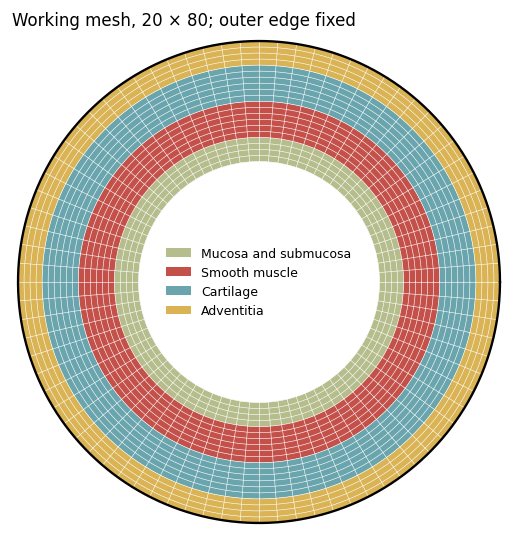

In [2]:
radii = ContinuumAirway(*WORKING).reference_radii
circle = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(4.4, 4.4), layout="constrained")
for (label, color), inner, outer in zip(LAYERS.values(), [1, 1.2, 1.5, 1.8], [1.2, 1.5, 1.8, 2]):
    ax.add_patch(Wedge((0, 0), outer, 0, 360, width=outer - inner, color=color, lw=0, label=label))
for r in radii:
    ax.plot(r * np.cos(circle), r * np.sin(circle), color="white", lw=.35)
for angle in np.linspace(0, 2 * np.pi, WORKING[1], endpoint=False):
    ax.plot(radii[[0, -1]] * np.cos(angle), radii[[0, -1]] * np.sin(angle), color="white", lw=.35)
ax.plot(2 * np.cos(circle), 2 * np.sin(circle), color="black", lw=1.4)
ax.set(aspect="equal", xlim=(-2.05, 2.05), ylim=(-2.05, 2.05), title="Working mesh, 20 × 80; outer edge fixed")
ax.axis("off")
ax.legend(loc="center", fontsize=7.5)
plt.show()

### Passive wall

Each layer is a compressible neo-Hookean solid in plane strain, with deformation gradient $F$ and
$J = \det F$:

$$
W = \frac{\mu}{2}\left(\operatorname{tr} F^{\mathsf T}F - 2\right) - \mu \ln J + \frac{\lambda}{2}(\ln J)^2,
\qquad \mu = \frac{E}{2(1+\nu)}, \quad \lambda = \frac{E\nu}{(1+\nu)(1-2\nu)}.
$$

The energy is integrated over bilinear quadrilaterals with 2 × 2 Gauss quadrature. Geometry and loading
are rotationally symmetric, so Newton's method solves for one radius per node ring. An equilibrium is
accepted when the force on every free node, divided by its tributary area, is below $10^{-7}$. A
continuum is used rather than a spring network because a network's effective stiffness depends on
element shape, so refining it changes the material.

### Active tension

Muscle adds work along the reference circumferential direction $\mathbf t_0$:

$$
W_a = T\left(\lvert F\mathbf t_0 \rvert - 1\right), \qquad T = T_{\max}\,(AM_p + AM), \quad T_{\max} = 20.
$$

Tension is proportional to the attached fraction, with cycling and latch bridges bearing load equally
(Hai and Murphy 1988, p. C87).

### Cross-bridge kinetics

[Hai and Murphy's four-state scheme](https://doi.org/10.1152/ajpcell.1988.255.1.C86) tracks the fractions
of myosin that are detached ($M$), detached and phosphorylated ($M_p$), attached and phosphorylated
($AM_p$), and attached but dephosphorylated, the latch state ($AM$):

$$
\begin{aligned}
\dot M &= -k_1 M + k_2 M_p + k_7 AM, \\
\dot M_p &= k_1 M - (k_2 + k_3) M_p + k_4 AM_p, \\
\dot{AM}_p &= k_3 M_p - (k_4 + k_5) AM_p + k_6 AM, \\
\dot{AM} &= k_5 AM_p - (k_6 + k_7) AM.
\end{aligned}
$$

The kinase input $k_1 = k_6 = k(t)$ is prescribed. The other rates are the published values, fitted to
swine carotid artery (p. C86): $k_2 = k_5 = 0.5$, $k_3 = 0.4$, $k_4 = 0.1$ and $k_7 = 0.01\ \mathrm{s^{-1}}$.
Populations are advanced exactly, with the matrix exponential, over each interval of constant input.

### Coupling

The wall is assumed to equilibrate much faster than cross-bridges cycle, so each output time is an
independent static equilibrium at the current attached fraction.

## Results

### Mesh convergence

Narrowing at full activation, on meshes refined radially, angularly and in both directions up to
80 radial intervals × 160 sectors.

20 × 80: 5.3506%   80 × 160: 5.3510%   difference 0.0004 percentage points


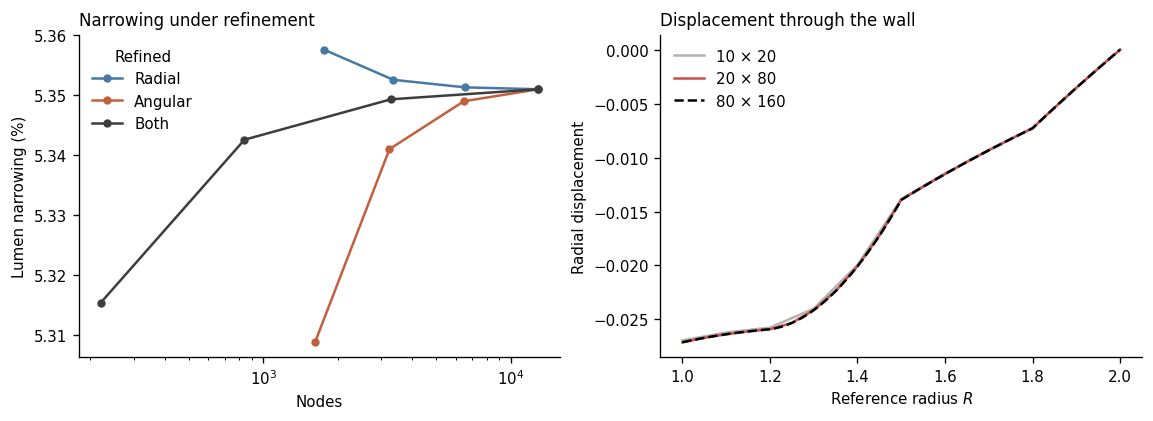

In [3]:
PATHS = {"Radial": [(n, 160) for n in (10, 20, 40, 80)],
         "Angular": [(80, n) for n in (20, 40, 80, 160)],
         "Both": [(10, 20), (20, 40), (40, 80), (80, 160)]}
mesh_runs = {resolution: equilibrium(resolution)
             for resolution in sorted({*sum(PATHS.values(), []), WORKING})}
working, finest = mesh_runs[WORKING], mesh_runs[FINEST]
gap = abs(working["narrowing_percent"] - finest["narrowing_percent"])
print(f"20 × 80: {working['narrowing_percent']:.4f}%   80 × 160: {finest['narrowing_percent']:.4f}%   "
      f"difference {gap:.4f} percentage points")

fig, (left, right) = plt.subplots(1, 2, figsize=(9.5, 3.4), layout="constrained")
for (name, path), color in zip(PATHS.items(), ["#4779a5", "#c1603e", "#3d3d3d"]):
    nodes = [(radial + 1) * sectors for radial, sectors in path]
    left.plot(nodes, [mesh_runs[p]["narrowing_percent"] for p in path], "o-", color=color, ms=4, label=name)
left.set(xscale="log", xlabel="Nodes", ylabel="Lumen narrowing (%)", title="Narrowing under refinement")
left.legend(title="Refined")
for resolution, style in [((10, 20), dict(color="0.7")), (WORKING, dict(color=LAYERS["muscle"][1])),
                          (FINEST, dict(color="black", ls="--"))]:
    run = mesh_runs[resolution]
    right.plot(run["reference_radii"], run["radii"] - run["reference_radii"], label=f"{resolution[0]} × {resolution[1]}", **style)
right.set(xlabel="Reference radius $R$", ylabel="Radial displacement", title="Displacement through the wall")
right.legend()
plt.show()

The working mesh is within a thousandth of a percentage point of the finest mesh and is used for
everything below. The lumen moves inward and the displacement falls to zero at the fixed outer edge.

### Kinetics against the published solution

At steady state, Hai and Murphy give closed-form apparent attachment and detachment rates
(Eqs. 3–4, p. C87). With $D = k_4 k_6 + k_4 k_7 + k_5 k_7$,

$$
f = \frac{k_1 k_3 D}{(k_1 + k_2) D + k_3 k_5 k_7}, \qquad g = \frac{D}{k_5 + k_6 + k_7}.
$$

The same rates follow from the numerical steady-state populations as $f = k_3 M_p/(M + M_p)$ and
$g = (k_4 AM_p + k_7 AM)/(AM_p + AM)$.

Largest difference from the published equations: 5.6e-17 1/s


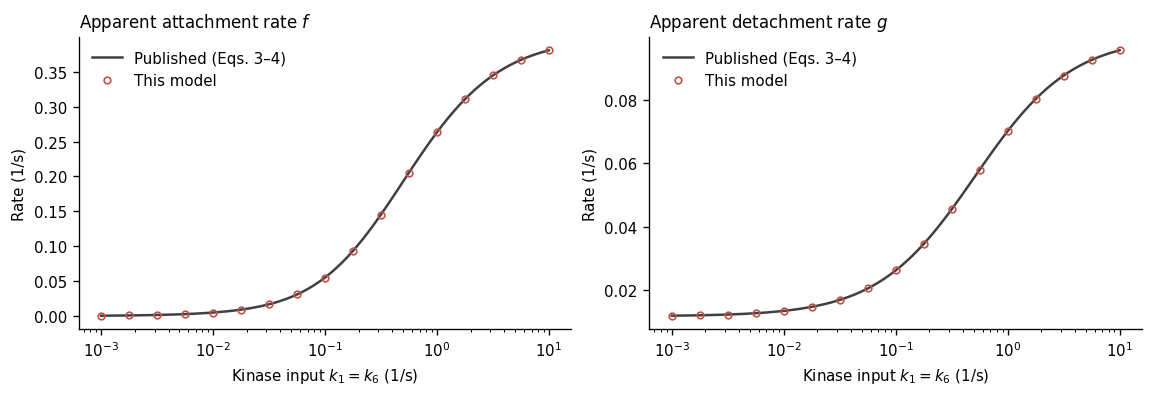

In [4]:
rates = HaiMurphyRates()
kinase = np.logspace(-3, 1, 81)
steady = np.array([rates.steady_state(k) for k in kinase])
f_numerical = rates.k3 * steady[:, 1] / steady[:, :2].sum(axis=1)
g_numerical = (rates.k4 * steady[:, 2] + rates.k7 * steady[:, 3]) / steady[:, 2:].sum(axis=1)
D = rates.k4 * kinase + rates.k4 * rates.k7 + rates.k5 * rates.k7
f_published = kinase * rates.k3 * D / ((kinase + rates.k2) * D + rates.k3 * rates.k5 * rates.k7)
g_published = D / (rates.k5 + kinase + rates.k7)
error = max(np.abs(f_numerical - f_published).max(), np.abs(g_numerical - g_published).max())
print(f"Largest difference from the published equations: {error:.1e} 1/s")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), layout="constrained")
for ax, published, numerical, title in zip(axes, [f_published, g_published], [f_numerical, g_numerical],
                                           ["Apparent attachment rate $f$", "Apparent detachment rate $g$"]):
    ax.semilogx(kinase, published, color="0.25", label="Published (Eqs. 3–4)")
    ax.semilogx(kinase[::5], numerical[::5], "o", ms=4, mfc="none", color=LAYERS["muscle"][1], label="This model")
    ax.set(xlabel="Kinase input $k_1 = k_6$ (1/s)", ylabel="Rate (1/s)", title=title)
    ax.legend()
plt.show()

### Activation and relaxation

Starting from rest, the kinase input is $0.55\ \mathrm{s^{-1}}$ from 10 to 30 s, $0.10\ \mathrm{s^{-1}}$
until 120 s, then zero.

Peak narrowing 4.087% at 30.5 s; phosphorylated 43%
At 120 s: narrowing 3.613%; phosphorylated 17%
At 600 s: narrowing 0.030%


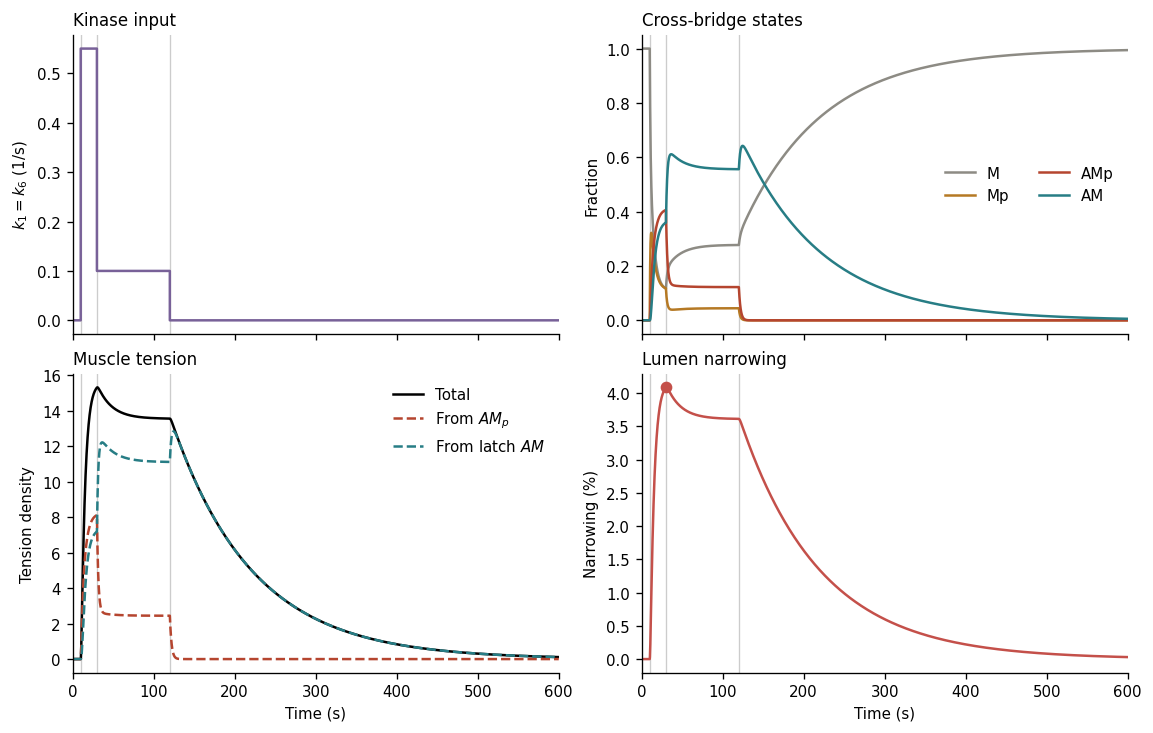

In [5]:
protocol = ActivationProtocol((0, 10, 30, 120), (0, 0.55, 0.10, 0))
# 0.25 s sampling through the fast phases, 1.25 s during the slow latch tail.
times = np.r_[np.arange(0, 160.25, .25), np.arange(161.25, 600.01, 1.25)]
states = simulate(times, protocol, rates=rates)
wall = quasistatic_response(states, radial_intervals=WORKING[0], sectors=WORKING[1], moduli=MODULI,
                            poisson_ratio=POISSON, tension_scale=T_MAX, force_density_tol=TOLERANCE)
narrowing = wall["narrowing_percent"]
phosphorylated = states[:, 1] + states[:, 2]
peak, withdrawal = int(np.argmax(narrowing)), int(np.flatnonzero(times == 120)[0])
print(f"Peak narrowing {narrowing[peak]:.3f}% at {times[peak]:.1f} s; phosphorylated {phosphorylated[peak]:.0%}")
print(f"At 120 s: narrowing {narrowing[withdrawal]:.3f}%; phosphorylated {phosphorylated[withdrawal]:.0%}")
print(f"At 600 s: narrowing {narrowing[-1]:.3f}%")

fig, axes = plt.subplots(2, 2, figsize=(9.5, 6), layout="constrained", sharex=True)
axes[0, 0].step(times, protocol.values(times), where="post", color=KINASE_COLOR)
axes[0, 0].set(ylabel="$k_1 = k_6$ (1/s)", title="Kinase input")
for i, (name, color) in enumerate(zip(STATE_NAMES, STATE_COLORS)):
    axes[0, 1].plot(times, states[:, i], color=color, label=name)
axes[0, 1].set(ylabel="Fraction", title="Cross-bridge states")
axes[0, 1].legend(ncol=2)
axes[1, 0].plot(times, wall["tension_density"], color="black", label="Total")
axes[1, 0].plot(times, T_MAX * states[:, 2], "--", color=STATE_COLORS[2], label="From $AM_p$")
axes[1, 0].plot(times, T_MAX * states[:, 3], "--", color=STATE_COLORS[3], label="From latch $AM$")
axes[1, 0].set(xlabel="Time (s)", ylabel="Tension density", title="Muscle tension")
axes[1, 0].legend()
axes[1, 1].plot(times, narrowing, color=LAYERS["muscle"][1])
axes[1, 1].plot(times[peak], narrowing[peak], "o", color=LAYERS["muscle"][1])
axes[1, 1].set(xlabel="Time (s)", ylabel="Narrowing (%)", title="Lumen narrowing")
for ax in axes.flat:
    for switch in protocol.switch_times[1:]:
        ax.axvline(switch, color="0.8", lw=.8, zorder=0)
    ax.set_xlim(0, 600)
plt.show()

The strong input phosphorylates myosin within seconds and the lumen narrows to its peak. When the input
drops, phosphorylation falls from 43% to 17%, but dephosphorylated latch bridges keep almost 90% of the
narrowing. After withdrawal, phosphorylation disappears within seconds ($1/k_2 = 2$ s) and the remaining
tension decays as latch bridges detach ($1/k_7 = 100$ s), leaving 0.03% narrowing at 600 s.

### Wall stiffness and activation

The three non-muscle moduli are scaled together from 0.25× to 4× with the muscle modulus fixed, and a
prescribed activation $a$ replaces $AM_p + AM$ in the tension law.

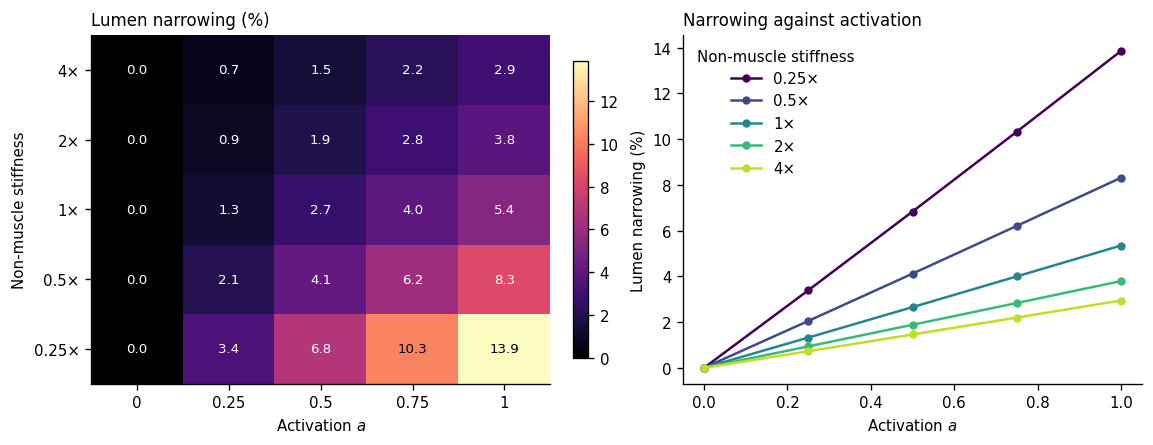

In [6]:
multipliers = [0.25, 0.5, 1.0, 2.0, 4.0]
activations = [0.0, 0.25, 0.5, 0.75, 1.0]
sweep = {(s, a): equilibrium(multiplier=s, activation=a) for s in multipliers for a in activations}
grid = np.array([[sweep[s, a]["narrowing_percent"] for a in activations] for s in multipliers])

fig, (left, right) = plt.subplots(1, 2, figsize=(9.5, 3.6), layout="constrained")
image = left.imshow(grid, origin="lower", cmap="magma", aspect="auto")
for (row, column), value in np.ndenumerate(grid):
    left.text(column, row, f"{value:.1f}", ha="center", va="center", fontsize=8,
              color="white" if value < .6 * grid.max() else "black")
left.set(xticks=range(5), xticklabels=[f"{a:g}" for a in activations], xlabel="Activation $a$",
         yticks=range(5), yticklabels=[f"{s:g}×" for s in multipliers], ylabel="Non-muscle stiffness",
         title="Lumen narrowing (%)")
fig.colorbar(image, ax=left, shrink=.85)
for s, color in zip(multipliers, plt.get_cmap("viridis")(np.linspace(0, .9, 5))):
    right.plot(activations, grid[multipliers.index(s)], "o-", ms=4, color=color, label=f"{s:g}×")
right.set(xlabel="Activation $a$", ylabel="Lumen narrowing (%)", title="Narrowing against activation")
right.legend(title="Non-muscle stiffness")
plt.show()

Narrowing grows with activation at every stiffness, and stiffer surrounding tissue resists it: at full
activation it falls from 13.9% at 0.25× to 2.9% at 4×.

## Limitations

- The kinetic rates were fitted to swine carotid artery, not airway smooth muscle.
- Geometry, moduli and tension are dimensionless and uncalibrated, so the percentages show trends rather
  than predictions.
- The coupling is one-way and quasistatic: there is no wall viscosity, force–velocity relation, or strain
  feedback on the kinetics.
- Only rotationally symmetric deformation is solved, so mucosal folding and buckling are excluded.

## Saved results

The browser app's parity tests (`npm test` in `frontend/`) compare its solver against these files.

In [7]:
def save(name, report):
    path = BACKEND / "results" / name
    path.parent.mkdir(exist_ok=True)
    path.write_text(json.dumps(report, indent=1, allow_nan=False) + "\n")
    print("Saved", path)


wall_settings = {"moduli": MODULI, "poisson_ratio": POISSON, "maximum_tension_density": T_MAX,
                 "force_density_tolerance": TOLERANCE, "units": "dimensionless"}
save("mesh_convergence.json", {**wall_settings, "activation": 1.0, "cases": [
    {"radial_intervals": radial, "sectors": sectors, "narrowing_percent": run["narrowing_percent"],
     "lumen_area": run["lumen_area"], "residual_density": run["residual_density"],
     "minimum_jacobian": run["minimum_jacobian"], "reference_radii": run["reference_radii"].tolist(),
     "radii": run["radii"].tolist()} for (radial, sectors), run in mesh_runs.items()]})
save("stiffness_sweep.json", {**wall_settings, "radial_intervals": WORKING[0], "sectors": WORKING[1], "cases": [
    {"stiffness_multiplier": s, "activation": a, "narrowing_percent": run["narrowing_percent"],
     "radial_displacement": (run["radii"] - run["reference_radii"]).tolist()} for (s, a), run in sweep.items()]})
save("time_course.json", {**wall_settings, "radial_intervals": WORKING[0], "sectors": WORKING[1],
    "rates_per_second": asdict(rates), "switch_times_seconds": list(protocol.switch_times),
    "kinase_rates_per_second": list(protocol.kinase_rates), "state_order": list(STATE_NAMES),
    "time_seconds": times.tolist(), "states": states.tolist(),
    "wall": {key: wall[key].tolist() for key in ("radii", "narrowing_percent", "tension_density",
                                                 "lumen_area", "residual_density", "minimum_jacobian")},
    "peak_time_seconds": float(times[peak]), "peak_narrowing_percent": float(narrowing[peak]),
    "final_narrowing_percent": float(narrowing[-1])})

Saved results/mesh_convergence.json
Saved results/stiffness_sweep.json
Saved results/time_course.json
